# IAT=30 high/low 分组的 FC 表征基础：Schaefer200 GMM full confirmatory analysis

本 notebook 只保留 **Schaefer200 cortical ROI + Harvard-Oxford 14 subcortical ROI** 的确认性分析。

代码流程尽量与 `CPM_nestedCV-LOOCV.ipynb` 保持一致：

1. 从 `DATA_ROOT` 读取量表和 ROI time series；
2. 逐被试计算 Fisher-z FC edge matrix；
3. 控制基本协变量后，对 FC profile 做 PCA embedding；
4. 在两个预先指定的 embedding 中运行 `GaussianMixture(covariance_type="full")`；
5. 用 label permutation 检查 GMM cluster 与 IAT=30 high/low 标签的对应关系是否显著。

核心科学问题：

> IAT=30 定义的 highIAT / lowIAT 分组，是否在控制协变量后的 Schaefer200+HO14 FC 表征中具有可验证、可重复的弱神经表征基础？


## 0. CPU / thread configuration

限制 BLAS/OpenMP 的内部线程数，避免 `joblib` 并行时再叠加底层多线程，导致 CPU 抢占和速度下降。`N_JOBS_PERM` 用于 permutation。


In [1]:
# ============================================================
# 0. CPU / thread configuration
#    建议重启 kernel 后，从这个 cell 开始运行
# ============================================================

import os


# 避免 joblib 多进程 + BLAS 多线程嵌套抢核；Mac Studio 上通常更快更稳
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

N_CPU = os.cpu_count() or 20
N_JOBS_PERM = max(1, min(18, N_CPU - 2))

print(f"Detected CPU cores: {N_CPU}")
print(f"N_JOBS_PERM={N_JOBS_PERM}")


Detected CPU cores: 24
N_JOBS_PERM=18


## 1. Imports

导入基础科学计算、GMM、评价指标、并行计算和绘图模块，并把 `DATA_ROOT` 与项目 `Scripts` 加入 `sys.path`，确保优先复用当前正在整理的 `biox` 函数。


In [2]:
# ============================================================
# 1. Imports
# ============================================================

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.mixture import GaussianMixture

import matplotlib.pyplot as plt

# 与 CPM_nestedCV-LOOCV.ipynb 保持同一套根目录约定。
DATA_ROOT = Path.home() / "Desktop" / "YiZhang"

# CPM_new.py 当前位于本项目 Scripts/biox 中；把 Scripts 放在 sys.path 前端，
# 确保优先复用正在重构的新 biox 模块。
SCRIPTS_DIR = Path("/Users/yiling/Documents/Codex/HBN_Cdx/Scripts")
for package_root in [DATA_ROOT, SCRIPTS_DIR]:
    if str(package_root) not in sys.path:
        sys.path.insert(0, str(package_root))

from biox.prep import compute_fc_from_timeseries_dirs
from biox.ML import (
    make_pca_embeddings,
    test_binary_cluster_alignment,
)
from biox.CPM_new import (
    _design_matrix,
    _residualize_with_C,
    _select_finite_variance_columns,
    _validate_array,
)

print("DATA_ROOT:", DATA_ROOT)
print("SCRIPTS_DIR:", SCRIPTS_DIR)
print("Imported biox.prep.compute_fc_from_timeseries_dirs, biox.ML tools, and biox.CPM_new residualization helpers")


DATA_ROOT: /Users/fmri24/Desktop/YiZhang
SCRIPTS_DIR: /Users/yiling/Documents/Codex/HBN_Cdx/Scripts
Imported biox.prep.compute_fc_from_timeseries_dirs, biox.ML tools, and biox.CPM_new residualization helpers


## 2. 路径与全局参数

集中定义输入路径、Schaefer200+HO14 atlas 设置、IAT/CBCL 筛选阈值、协变量、PCA embedding 维度、GMM 参数以及 permutation 次数。后续分析只从这里读取这些常量。


In [3]:
# ============================================================
# 2. 路径与全局参数
# ============================================================

SCALE_CSV = DATA_ROOT / "量表数据汇总_with_MeanEnorm.csv"

# 本脚本固定分析 Schaefer200 + HO14。
SCHAEFER_N_ROIS = 200
SCHAEFER_DIR = DATA_ROOT / "HBN_func_Schaefer200"
HO_DIR = DATA_ROOT / "HBN_func_HarvardOxfordSubcortical"

# Harvard-Oxford 原始 ROI 下标。这里沿用主 CPM 脚本中的写法：
# 原始编号为 1-based，因此转换为 Python 0-based index 时需要减 1。
HO_RAW_INDEX = np.array([4, 5, 6, 7, 9, 10, 11, 15, 16, 17, 18, 19, 20, 21]) - 1

IAT_LABEL = "IAT_PCIAT_Total"
SITE_COL = "ScannerSite"
CBCL_TOTAL_COL = "CBCL,CBCL_Total_T"
MOTION_COL = "mean_enorm"

# GMM 之前先从 FC 中回归掉这些协变量。
# IAT 不在协变量中：IAT 只用来定义 high/low 标签和评估 cluster 对应关系。
COVARIATE_COLS = [
    "Basic_Demos,Age",
    "Basic_Demos,Sex",
    "Barratt,Barratt_Total_Edu",
    "Barratt,Barratt_Total_Occ",
    "CBCL,CBCL_Int_T",
    "CBCL,CBCL_Ext_T",
    MOTION_COL,
]

EXPECTED_N_TIMEPOINTS = 740
CBCL_MAX = 70
ENORM_CUTOFF = 0.3
IAT_CUTOFF = 30

OUT_DIR = DATA_ROOT / "CPM_GMM"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# PCA embedding 默认使用 50 个 PC；若后续想测试 PC30/PC100，只需修改这里。
PC_EMBEDDING_N_COMPONENTS = 50

EMBEDDING_NAMES = [
    f"PC{PC_EMBEDDING_N_COMPONENTS}_scaled",
    f"PC{PC_EMBEDDING_N_COMPONENTS}_removePC1_scaled",
]

# GMM full covariance 固定参数。
GMM_N_COMPONENTS = 2
GMM_COVARIANCE_TYPE = "full"
GMM_N_INIT = 30
GMM_REG_COVAR = 1e-5
GMM_MAX_ITER = 1000

# 显著性检验。
N_PERM = 5000

RANDOM_STATE = 2026

print("SCALE_CSV:", SCALE_CSV)
print("SCHAEFER_DIR:", SCHAEFER_DIR)
print("HO_DIR:", HO_DIR)
print("OUT_DIR:", OUT_DIR)


SCALE_CSV: /Users/fmri24/Desktop/YiZhang/量表数据汇总_with_MeanEnorm.csv
SCHAEFER_DIR: /Users/fmri24/Desktop/YiZhang/HBN_func_Schaefer200
HO_DIR: /Users/fmri24/Desktop/YiZhang/HBN_func_HarvardOxfordSubcortical
OUT_DIR: /Users/fmri24/Desktop/YiZhang/CPM_GMM


## 3. FC 计算

本节复用 `biox.prep.compute_fc_from_timeseries_dirs()` 从已经提取好的 ROI time series 文件计算 Fisher-z FC edges。这里的 `roi_timeseries_sources` 指不同 atlas/parcellation 的 ROI time series 目录，例如 cortical Schaefer200 和 subcortical HO14；函数会先在每个来源内拼接 run，再把不同来源沿 ROI 维拼接，最后计算 FC。

因此，本节只需要说明当前分析使用哪些 ROI time series 来源、每个来源读取哪些 run、是否保留 ROI subset，以及文件命名规则；逐被试 `np.load()`、`np.corrcoef()` 和 edge vectorization 都交给 `biox` 函数完成。


In [4]:
# ============================================================
# 3. FC 计算 / 数据读取
# ============================================================

# 1) 读取量表总表。df_raw 是原始表型表；df_fc 是成功计算 FC 的被试表，
#    与 FC_all 严格按行对齐。
df_raw = pd.read_csv(SCALE_CSV)
df_raw["ID"] = df_raw["ID"].astype(str)

# 2) 用 roi_timeseries_sources 描述不同 atlas/parcellation 的 ROI time series 来源。
#    这里的“来源”不是 atlas 图谱文件本身，而是已经提前提取好的 .npy
#    time series 目录。每个来源可以指定自己的 run_labels 和 ROI subset。
#
#    - Schaefer200：cortical atlas，读取全部 200 个 cortical ROI；
#    - HO14：subcortical atlas，读取 HO_DIR 中的 time series，并只保留
#      HO_RAW_INDEX 指定的 14 个 subcortical ROI。
#
#    compute_fc_from_timeseries_dirs() 会对每个被试执行：
#    先在同一来源内沿时间维拼接 func1/func2，再把 Schaefer200 与 HO14
#    沿 ROI 维拼接，最后计算统一的 Schaefer200+HO14 FC。
roi_timeseries_sources = [
    {"name": "Schaefer200", "data_dir": SCHAEFER_DIR, "run_labels": ("func1", "func2")},
    {"name": "HO14", "data_dir": HO_DIR, "run_labels": ("func1", "func2"), "roi_index": HO_RAW_INDEX},
]

# 3) 从 ROI time series 直接计算 Fisher-z FC edge matrix。
#    return_edges=True 表示返回 shape=(n_subjects, n_edges) 的 FC edge matrix，
#    适合后续 residualization、PCA 和 GMM。函数内部会打印 FC 数据准备摘要，
#    包括成功保留/排除的被试数，以及缺文件、时间点数异常、shape 错误等
#    排除原因。
df_fc, FC_all = compute_fc_from_timeseries_dirs(
    df=df_raw,
    roi_timeseries_sources=roi_timeseries_sources,
    subject_id_col="ID",
    file_template="sub-{subject_id}_{run_label}.npy",
    drop_initial_timepoints=0,
    expected_n_timepoints=EXPECTED_N_TIMEPOINTS,
    fisher_z=True,
    return_edges=True,
)

print("df_fc:", df_fc.shape)
print("FC_all:", FC_all.shape)


FC data preparation summary:
  n_input_subjects: 1387
  n_kept_subjects: 1376
  n_excluded_subjects: 11
Excluded subjects by reason:
  bad_timepoints: 8
  missing: 3
Excluded subject details:
  subject_id=NDARDY714NV9, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARFJ803JF7, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARHW968ABB, reason=bad_timepoints, source=Schaefer200, observed_timepoints=668, expected_timepoints=740
  subject_id=NDARJF579EH9, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARLB671TLU, reason=bad_timepoints, source=Schaefer200, observed_timepoints=659, expected_timepoints=740
  subject_id=NDARLH881FBD, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARUF152ARR, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730,

## 4. 模型样本、IAT 标签与协变量

本节在 `df_fc / FC_all` 的基础上继续筛选真正进入 GMM 分析的被试，并生成 `df_model`、`FC_model`、IAT high/low 标签和协变量矩阵。


In [5]:
# ============================================================
# 4. 模型样本、IAT 标签与协变量
# ============================================================

# 4.1 表型与 FC 有效样本筛选。
# 要求：基本协变量、IAT、CBCL total 和 ScannerSite 均非缺失，且 CBCL total < 70。
numeric_cols = COVARIATE_COLS + [IAT_LABEL, CBCL_TOTAL_COL]
for col in numeric_cols:
    if col not in df_fc.columns:
        raise KeyError(f"Column not found: {col}")
    df_fc[col] = pd.to_numeric(df_fc[col], errors="coerce")

required_cols = COVARIATE_COLS + [IAT_LABEL, CBCL_TOTAL_COL, SITE_COL]
iat_values = df_fc[IAT_LABEL].to_numpy(dtype=float)
cbcl_total_values = df_fc[CBCL_TOTAL_COL].to_numpy(dtype=float)
motion_values = df_fc[MOTION_COL].to_numpy(dtype=float)
valid_pheno = (
    df_fc[required_cols].notna().all(axis=1).to_numpy()
    & np.isfinite(iat_values)
    & np.isfinite(cbcl_total_values)
    & np.isfinite(motion_values)
    & (motion_values < ENORM_CUTOFF)
    & (cbcl_total_values < CBCL_MAX)
)

FC_model = FC_all[valid_pheno, :]
df_model = df_fc.loc[valid_pheno].reset_index(drop=True).copy()

valid_fc = np.isfinite(FC_model).all(axis=1)
FC_model = FC_model[valid_fc, :]
df_model = df_model.loc[valid_fc].reset_index(drop=True).copy()

# 4.2 IAT=30 high/low 标签。
y_iat = df_model[IAT_LABEL].to_numpy(dtype=float)
y_group = (y_iat > IAT_CUTOFF).astype(int)  # 1=highIAT, 0=lowIAT
group_name = np.where(y_group == 1, "highIAT", "lowIAT")

# 4.3 协变量矩阵：连续/二值协变量 + ScannerSite dummy。
cov_basic = df_model[COVARIATE_COLS].to_numpy(dtype=float)
cov_names = list(COVARIATE_COLS)
site_dummies_df = pd.get_dummies(
    df_model[SITE_COL].astype(str),
    prefix=SITE_COL,
    drop_first=True,
)
if site_dummies_df.shape[1] > 0:
    covariates = np.column_stack([cov_basic, site_dummies_df.to_numpy(dtype=float)])
    cov_names = cov_names + list(site_dummies_df.columns)
else:
    covariates = cov_basic

analysis_info = {
    "N": int(len(y_group)),
    "n_edges": int(FC_model.shape[1]),
    "n_covariates": int(covariates.shape[1]),
    "n_lowIAT": int(np.sum(y_group == 0)),
    "n_highIAT": int(np.sum(y_group == 1)),
    "IAT_cutoff": float(IAT_CUTOFF),
    "CBCL_filter": f"{CBCL_TOTAL_COL} < {CBCL_MAX}",
    "IAT_mean": float(np.mean(y_iat)),
    "IAT_sd": float(np.std(y_iat, ddof=1)),
    "covariates": cov_names,
}

print("Data info:")
print(json.dumps(analysis_info, ensure_ascii=False, indent=2))


Data info:
{
  "N": 1114,
  "n_edges": 22791,
  "n_covariates": 10,
  "n_lowIAT": 653,
  "n_highIAT": 461,
  "IAT_cutoff": 30.0,
  "CBCL_filter": "CBCL,CBCL_Total_T < 70",
  "IAT_mean": 27.447935368043087,
  "IAT_sd": 14.909339085280743,
  "covariates": [
    "Basic_Demos,Age",
    "Basic_Demos,Sex",
    "Barratt,Barratt_Total_Edu",
    "Barratt,Barratt_Total_Occ",
    "CBCL,CBCL_Int_T",
    "CBCL,CBCL_Ext_T",
    "mean_enorm",
    "ScannerSite_CUNY",
    "ScannerSite_RU",
    "ScannerSite_RU_ex"
  ]
}


## 5. FC residualization 与 PCA embedding

本节先控制协变量得到 residualized FC，再删除无效/零方差 edges，进行 z-score，并复用 `biox.ML.make_pca_embeddings()` 生成两个确认性 PCA embeddings。


In [6]:
# ============================================================
# 5. FC residualization 与 PCA embedding
# ============================================================

# 5.1 控制协变量：对每条 FC edge 回归 C = [intercept, covariates]。
print("Residualizing FC by covariates...")
FC_model = _validate_array(FC_model, name="FC_model", ndim=2)
C = _design_matrix(covariates, FC_model.shape[0])
FC_resid, _ = _residualize_with_C(FC_model, C)
FC_resid = FC_resid.astype(np.float32)

# 5.2 PCA 前标准化 FC edges。
# 先删除含 NaN/Inf 或方差近似为 0 的 edge，再对保留 edge 做全样本 z-score。
print("Z-scoring residualized FC edges...")
keep_edges = _select_finite_variance_columns(FC_resid, eps=1e-8)
FC_keep = FC_resid[:, keep_edges]
edge_mean = FC_keep.mean(axis=0, keepdims=True)
edge_sd = FC_keep.std(axis=0, keepdims=True)
edge_sd[edge_sd < 1e-8] = 1.0
FC_z = ((FC_keep - edge_mean) / edge_sd).astype(np.float32)
print(f"FC_z shape: {FC_z.shape}; kept edges: {int(np.sum(keep_edges))}/{FC_model.shape[1]}")

# 5.3 生成两个确认性 PCA embeddings。
print("Making confirmatory PCA embeddings...")
Z_scaled, Z_removePC1_scaled, pca, pca_var = make_pca_embeddings(
    FC_z,
    n_embedding_components=PC_EMBEDDING_N_COMPONENTS,
    random_state=RANDOM_STATE,
)

pca_var_path = OUT_DIR / f"Schaefer{SCHAEFER_N_ROIS}_HO14_pca_variance.csv"
pca_var.to_csv(pca_var_path, index=False)
print(f"Saved: {pca_var_path}")

embedding_inputs = [
    (EMBEDDING_NAMES[0], Z_scaled),
    (EMBEDDING_NAMES[1], Z_removePC1_scaled),
]


Residualizing FC by covariates...
Z-scoring residualized FC edges...
FC_z shape: (1114, 22791); kept edges: 22791/22791
Making confirmatory PCA embeddings...
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_pca_variance.csv


## 6. 单个 embedding 的 GMM alignment

本节保留 `run_gmm_alignment_for_embedding()`，因为两个 PCA embedding 会重复使用同一套 GMM、permutation 和保存流程。


In [7]:
# ============================================================
# 6. GMM alignment for one embedding
# ============================================================

# 只保留会被重复调用的函数：每个 PCA embedding 都要用同一套 GMM、
# permutation 流程分析一次。样本筛选、协变量控制和 PCA 生成
# 已在前面章节完成，因此这里不再重复处理原始 FC。


def run_gmm_alignment_for_embedding(
    embedding_name,
    Z,
    y_group,
    group_name,
    y_iat,
    df_keep,
    random_state=2026,
):
    """
    对一个指定的 PCA embedding 运行 GMM label-alignment 分析。

    本函数的输入 Z 已经是准备好的低维 FC 表征，例如：
    - PC50_scaled：使用 PC1-PC50；
    - PC50_removePC1_scaled：去掉 PC1，使用 PC2-PC51。

    它不再处理原始 FC，也不再做协变量回归或 PCA。那些步骤已在前面的数据
    准备章节中完成。本函数只回答：在这个 embedding 空间中，
    GMM 分出的两个 cluster 是否对应 highIAT / lowIAT 分组，以及这种对应关系是否
    显著。

    Parameters
    ----------
    embedding_name : str
        当前 embedding 的名称，用于打印信息和构造输出文件名。
    Z : ndarray, shape (n_subjects, n_components)
        PCA 后的低维 FC 表征；每一行是一个被试，每一列是一个 PC score。
    y_group : ndarray, shape (n_subjects,)
        IAT=30 得到的二分类标签；1=highIAT，0=lowIAT。
    group_name : ndarray, shape (n_subjects,)
        与 y_group 对应的文字标签，主要用于保存 label_df。
    y_iat : ndarray, shape (n_subjects,)
        连续 IAT 分数。本函数只把它保存到 label_df，连续 IAT 的统计和可视化
        后续单独处理，不混入二分类 cluster alignment 指标。
    df_keep : pandas.DataFrame
        与 Z 顺序一致的被试信息表，用于保存每个被试的 GMM label 和 probability。
    random_state : int
        GMM 以及后续 permutation 分析的随机种子起点。

    Returns
    -------
    out : dict
        当前 embedding 的核心结果，包括 summary_df、列联表、permutation
        原始结果和逐被试 label 表。
    """
    print("-" * 100)
    print(f"Confirmatory GMM: Schaefer{SCHAEFER_N_ROIS}+HO14 | {embedding_name}")

    prefix = f"Schaefer{SCHAEFER_N_ROIS}_HO14_{embedding_name}_GMMfull"

    # 1) 在真实 embedding 上拟合 GMM。
    #    GMM 是无监督模型，并不知道 highIAT/lowIAT 标签；标签只在后面用于解释 cluster。
    gmm = GaussianMixture(
        n_components=GMM_N_COMPONENTS,
        covariance_type=GMM_COVARIANCE_TYPE,
        n_init=GMM_N_INIT,
        reg_covar=GMM_REG_COVAR,
        max_iter=GMM_MAX_ITER,
        random_state=random_state,
    )
    labels = gmm.fit_predict(Z)
    clustering_scores = gmm.predict_proba(Z).astype(float)

    # 2) Label permutation：固定 GMM labels，只打乱 high/lowIAT 标签。
    #    test_binary_cluster_alignment() 会在函数内部完成三件事：
    #    - 判断真实数据下哪个 GMM cluster 更像 highIAT；
    #    - 从 clustering_scores 中自动取出 highIAT-like cluster 的 probability；
    #    - 随机打乱 high/lowIAT 标签，生成 null distribution 和 permutation p 值。
    #    因此这里不再手动调用 evaluate_binary_cluster_alignment()。
    print("Running observed alignment and label permutation...")
    obs_metrics, tab, desc_df, pred_high, positive_score, perm_df = test_binary_cluster_alignment(
        labels=labels,
        y_binary=y_group,
        clustering_scores=clustering_scores,
        n_perm=N_PERM,
        random_state=random_state + 10,
        n_jobs=N_JOBS_PERM,
    )

    obs_metrics.update({
        "atlas": SCHAEFER_N_ROIS,
        "embedding": embedding_name,
        "method": "GMM_full_confirmatory",
        "n_components": GMM_N_COMPONENTS,
        "covariance_type": GMM_COVARIANCE_TYPE,
        "gmm_n_init": GMM_N_INIT,
        "gmm_reg_covar": GMM_REG_COVAR,
        "gmm_converged": bool(gmm.converged_),
        "gmm_n_iter": int(gmm.n_iter_),
        "gmm_lower_bound": float(gmm.lower_bound_),
    })

    print("Observed metrics and permutation p-values:")
    display(pd.DataFrame([obs_metrics]))
    print("Crosstab:")
    display(tab)
    # 3) 每个被试的 cluster 标签表，便于后续人工检查或画图。
    label_df = df_keep.copy()
    label_df["IAT"] = y_iat
    label_df["IAT_group_binary"] = y_group
    label_df["IAT_group"] = group_name
    label_df["GMM_cluster"] = labels
    label_df["GMM_positive_like_probability"] = positive_score
    label_df["GMM_cluster_interpretation"] = np.where(pred_high == 1, "highIAT-like", "lowIAT-like")

    # 4) 保存每个 embedding 的核心结果。
    summary_df = pd.DataFrame([obs_metrics])

    outputs = {
        f"{prefix}_summary.csv": (summary_df, False),
        f"{prefix}_crosstab.csv": (tab, True),
        f"{prefix}_cluster_desc.csv": (desc_df, False),
        f"{prefix}_labels.csv": (label_df, False),
        f"{prefix}_permutation_distribution.csv": (perm_df, False),
    }
    for filename, (df_out, keep_index) in outputs.items():
        out_path = OUT_DIR / filename
        df_out.to_csv(out_path, index=keep_index)
        print("Saved:", out_path)

    return {
        "summary_df": summary_df,
        "tab": tab,
        "desc_df": desc_df,
        "label_df": label_df,
        "perm_df": perm_df,
    }



## 7. 正式运行

本节只负责把第 5 节得到的两个 embedding 送入同一个 GMM 分析函数，并汇总保存结果。


In [8]:
# ============================================================
# 7. Run Schaefer200 × embedding confirmatory analyses
# ============================================================

print("=" * 100)
print(f"Atlas: Schaefer{SCHAEFER_N_ROIS}+HO14")

# 对两个 embedding 使用同一套 GMM/permutation 流程。
out_by_embedding = {}
for i, (embedding_name, Z) in enumerate(embedding_inputs):
    out_by_embedding[embedding_name] = run_gmm_alignment_for_embedding(
        embedding_name=embedding_name,
        Z=Z,
        y_group=y_group,
        group_name=group_name,
        y_iat=y_iat,
        df_keep=df_model,
        random_state=RANDOM_STATE + i,
    )

ALL_SUMMARY = pd.concat(
    [emb_out["summary_df"] for emb_out in out_by_embedding.values()],
    ignore_index=True,
)
all_summary_path = OUT_DIR / "ALL_GMMfull_confirmatory_summary.csv"
ALL_SUMMARY.to_csv(all_summary_path, index=False)

print(f"Saved: {all_summary_path}")

display(ALL_SUMMARY.sort_values(["balanced_accuracy", "cramers_v"], ascending=False))


Atlas: Schaefer200+HO14
----------------------------------------------------------------------------------------------------
Confirmatory GMM: Schaefer200+HO14 | PC50_scaled
Running observed alignment and label permutation...
Observed metrics and permutation p-values:


,cluster_positive_like,cluster_negative_like,positive_rate_difference,accuracy,balanced_accuracy,positive_score_auc,cramers_v,chi2_p,fisher_p,ARI,...,atlas,embedding,method,n_components,covariance_type,gmm_n_init,gmm_reg_covar,gmm_converged,gmm_n_iter,gmm_lower_bound
0,1,0,0.09381,0.524237,0.545708,0.580787,0.09073,0.00246,0.002166,-0.000093,...,200,PC50_scaled,GMM_full_confirmatory,2,full,30,0.00001,True,40,-69.061611


Crosstab:


target_group,negative,positive
cluster,,
0,275,152
1,378,309


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_scaled_GMMfull_summary.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_scaled_GMMfull_crosstab.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_scaled_GMMfull_cluster_desc.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_scaled_GMMfull_labels.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_scaled_GMMfull_permutation_distribution.csv
----------------------------------------------------------------------------------------------------
Confirmatory GMM: Schaefer200+HO14 | PC50_removePC1_scaled
Running observed alignment and label permutation...
Observed metrics and permutation p-values:


,cluster_positive_like,cluster_negative_like,positive_rate_difference,accuracy,balanced_accuracy,positive_score_auc,cramers_v,chi2_p,fisher_p,ARI,...,atlas,embedding,method,n_components,covariance_type,gmm_n_init,gmm_reg_covar,gmm_converged,gmm_n_iter,gmm_lower_bound
0,0,1,0.037591,0.513465,0.519299,0.528238,0.036265,0.22613,0.222873,-0.000254,...,200,PC50_removePC1_scaled,GMM_full_confirmatory,2,full,30,0.00001,True,44,-69.416031


Crosstab:


target_group,negative,positive
cluster,,
0,336,255
1,317,206


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_removePC1_scaled_GMMfull_summary.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_removePC1_scaled_GMMfull_crosstab.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_removePC1_scaled_GMMfull_cluster_desc.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_removePC1_scaled_GMMfull_labels.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PC50_removePC1_scaled_GMMfull_permutation_distribution.csv
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/ALL_GMMfull_confirmatory_summary.csv


,cluster_positive_like,cluster_negative_like,positive_rate_difference,accuracy,balanced_accuracy,positive_score_auc,cramers_v,chi2_p,fisher_p,ARI,...,atlas,embedding,method,n_components,covariance_type,gmm_n_init,gmm_reg_covar,gmm_converged,gmm_n_iter,gmm_lower_bound
0,1,0,0.093810,0.524237,0.545708,0.580787,0.090730,0.00246,0.002166,-0.000093,...,200,PC50_scaled,GMM_full_confirmatory,2,full,30,0.00001,True,40,-69.061611
1,0,1,0.037591,0.513465,0.519299,0.528238,0.036265,0.22613,0.222873,-0.000254,...,200,PC50_removePC1_scaled,GMM_full_confirmatory,2,full,30,0.00001,True,44,-69.416031


## 8. 结果筛选与解释表

本节把两个 embedding 的核心统计量整理到一个表中，方便快速比较哪一种 embedding 与 IAT=30 high/low 标签对应更强、permutation 显著性更清楚。


In [9]:
# ============================================================
# 8. Quick interpretation table
# ============================================================

important_cols = [
    "atlas", "embedding",
    "cluster_positive_like", "cluster_negative_like",
    "positive_rate_difference",
    "balanced_accuracy", "positive_score_auc", "cramers_v", "ARI", "NMI",
    "chi2_p", "fisher_p",
    "perm_p_balanced_accuracy", "perm_p_positive_score_auc", "perm_p_cramers_v", "perm_p_positive_rate_difference",
]
important_cols = [c for c in important_cols if c in ALL_SUMMARY.columns]

INTERPRET_TABLE = ALL_SUMMARY[important_cols].sort_values(
    ["positive_score_auc", "balanced_accuracy", "cramers_v"],
    ascending=False,
)

display(INTERPRET_TABLE)

interpret_path = OUT_DIR / "INTERPRET_GMMfull_confirmatory_key_results.csv"
INTERPRET_TABLE.to_csv(interpret_path, index=False)
print(f"Saved: {interpret_path}")



,atlas,embedding,cluster_positive_like,cluster_negative_like,positive_rate_difference,balanced_accuracy,positive_score_auc,cramers_v,ARI,NMI,chi2_p,fisher_p,perm_p_balanced_accuracy,perm_p_positive_score_auc,perm_p_cramers_v,perm_p_positive_rate_difference
0,200,PC50_scaled,1,0,0.093810,0.545708,0.580787,0.090730,-0.000093,0.006427,0.00246,0.002166,0.002599,0.000200,0.002599,0.002599
1,200,PC50_removePC1_scaled,0,1,0.037591,0.519299,0.528238,0.036265,-0.000254,0.001060,0.22613,0.222873,0.220356,0.107379,0.220356,0.220356


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/INTERPRET_GMMfull_confirmatory_key_results.csv


## 9. 可视化

基于前面保存和汇总的结果绘图，包括 GMM label 与 IAT 分组的对应程度、highIAT-like probability 的 AUC 和 ROC 曲线，以及 PCA explained variance ratio。


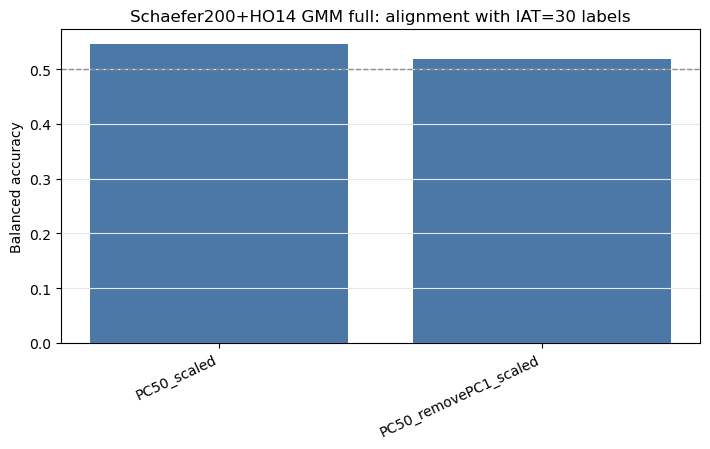

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_GMMfull_balanced_accuracy.png


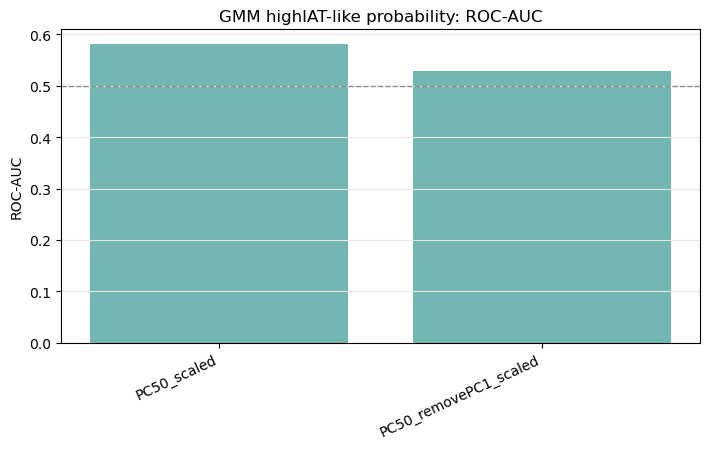

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_GMMfull_probability_auc.png


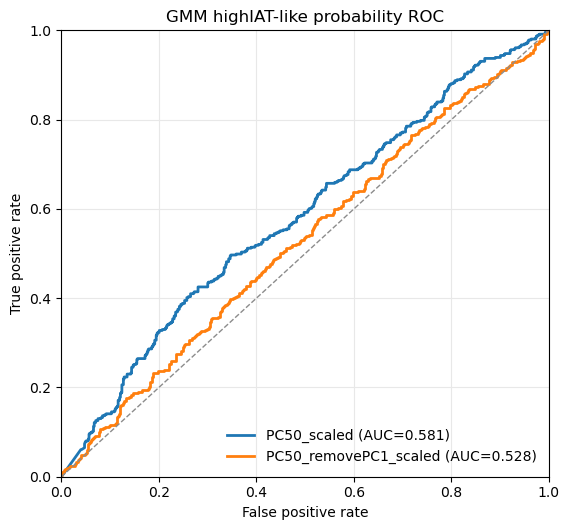

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_GMMfull_probability_ROC.png


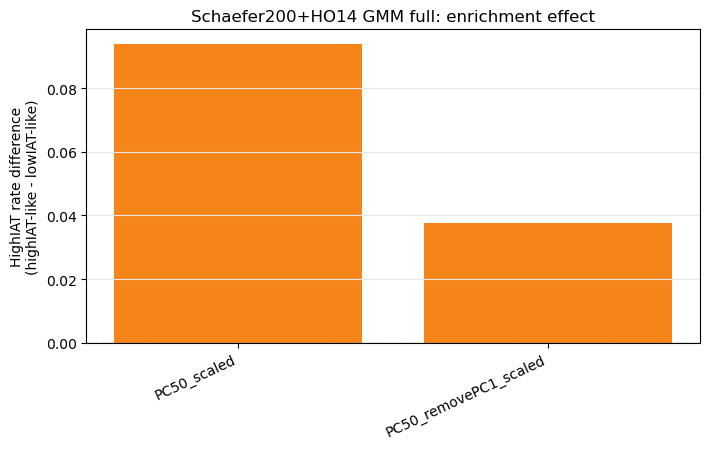

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_GMMfull_positive_rate_difference.png


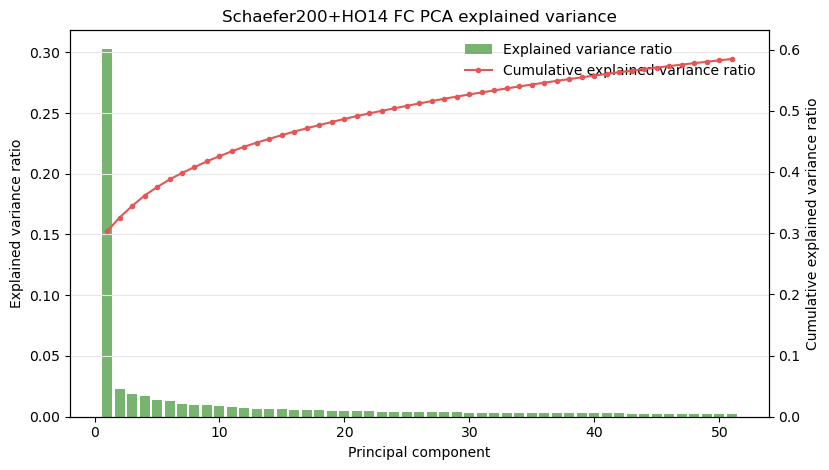

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM/Schaefer200_HO14_PCA_explained_variance_ratio.png


In [10]:
# ============================================================
# 9. Visualization
# ============================================================

plot_df = INTERPRET_TABLE.copy()
plot_df["label"] = plot_df["embedding"].astype(str)

# 9.1 GMM cluster 与 IAT high/low 标签的对应程度。
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(np.arange(len(plot_df)), plot_df["balanced_accuracy"].values, color="#4C78A8")
ax.axhline(0.5, color="#8c8c8c", linestyle="--", linewidth=1.0)
ax.set_xticks(np.arange(len(plot_df)))
ax.set_xticklabels(plot_df["label"].values, rotation=25, ha="right")
ax.set_ylabel("Balanced accuracy")
ax.set_title("Schaefer200+HO14 GMM full: alignment with IAT=30 labels")
ax.grid(True, axis="y", color="#e8e8e8", linewidth=0.8)
fig.tight_layout()
out_path = OUT_DIR / "Schaefer200_HO14_GMMfull_balanced_accuracy.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


# 9.2 GMM highIAT-like membership probability 的 AUC。
#       AUC 使用连续概率分数，不依赖固定 cluster 阈值，因此比二值 BAcc 更容易被读者理解。
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(np.arange(len(plot_df)), plot_df["positive_score_auc"].values, color="#72B7B2")
ax.axhline(0.5, color="#8c8c8c", linestyle="--", linewidth=1.0)
ax.set_xticks(np.arange(len(plot_df)))
ax.set_xticklabels(plot_df["label"].values, rotation=25, ha="right")
ax.set_ylabel("ROC-AUC")
ax.set_title("GMM highIAT-like probability: ROC-AUC")
ax.grid(True, axis="y", color="#e8e8e8", linewidth=0.8)
fig.tight_layout()
out_path = OUT_DIR / "Schaefer200_HO14_GMMfull_probability_auc.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

# 9.3 ROC 曲线。
#       注意：这里的曲线是 full-sample GMM alignment ROC，不是 cross-validated prediction ROC。
fig, ax = plt.subplots(figsize=(5.8, 5.4))
for embedding_name, emb_out in out_by_embedding.items():
    label_df = emb_out["label_df"]
    y_true = label_df["IAT_group_binary"].to_numpy(dtype=int)
    y_score = label_df["GMM_positive_like_probability"].to_numpy(dtype=float)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc_value = roc_auc_score(y_true, y_score)
    ax.plot(fpr, tpr, linewidth=2.0, label=f"{embedding_name} (AUC={auc_value:.3f})")

ax.plot([0, 1], [0, 1], color="#8c8c8c", linestyle="--", linewidth=1.0)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("GMM highIAT-like probability ROC")
ax.legend(frameon=False, loc="lower right")
ax.grid(True, color="#e8e8e8", linewidth=0.8)
fig.tight_layout()
out_path = OUT_DIR / "Schaefer200_HO14_GMMfull_probability_ROC.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(np.arange(len(plot_df)), plot_df["positive_rate_difference"].values, color="#F58518")
ax.axhline(0, color="#8c8c8c", linestyle="--", linewidth=1.0)
ax.set_xticks(np.arange(len(plot_df)))
ax.set_xticklabels(plot_df["label"].values, rotation=25, ha="right")
ax.set_ylabel("HighIAT rate difference\n(highIAT-like - lowIAT-like)")
ax.set_title("Schaefer200+HO14 GMM full: enrichment effect")
ax.grid(True, axis="y", color="#e8e8e8", linewidth=0.8)
fig.tight_layout()
out_path = OUT_DIR / "Schaefer200_HO14_GMMfull_positive_rate_difference.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

# 9.4 PCA explained_variance_ratio 可视化。
#      explained_variance_ratio 表示每个 PC 单独解释的 FC profile 方差比例；
#      cumulative_explained_variance_ratio 表示前 k 个 PC 累积解释的方差比例。
pca_var_plot = pca_var.copy()

fig, ax1 = plt.subplots(figsize=(8.4, 4.8))
ax1.bar(
    pca_var_plot["PC"],
    pca_var_plot["explained_variance_ratio"],
    color="#54A24B",
    alpha=0.80,
    label="Explained variance ratio",
)
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Explained variance ratio")
ax1.grid(True, axis="y", color="#e8e8e8", linewidth=0.8)

ax2 = ax1.twinx()
ax2.plot(
    pca_var_plot["PC"],
    pca_var_plot["cumulative_explained_variance_ratio"],
    color="#E45756",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Cumulative explained variance ratio",
)
ax2.set_ylabel("Cumulative explained variance ratio")
ax2.set_ylim(0, max(0.05, pca_var_plot["cumulative_explained_variance_ratio"].max() * 1.08))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", frameon=False)
ax1.set_title("Schaefer200+HO14 FC PCA explained variance")

fig.tight_layout()
out_path = OUT_DIR / "Schaefer200_HO14_PCA_explained_variance_ratio.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)
